In [2]:
from photutils.detection import DAOStarFinder
from astropy.stats import sigma_clipped_stats
from photutils.aperture import CircularAperture
from astropy.visualization import SqrtStretch
from astropy.visualization.mpl_normalize import ImageNormalize
from astropy.wcs import WCS
from astropy.io import fits
import glob
import os
from scipy.stats import scoreatpercentile

from matplotlib import pyplot as plt
import numpy as np

#import ccdproc

from astropy.nddata import CCDData
import astropy.units as u
from ccdproc import ImageFileCollection, Combiner, combine
from ccdproc import wcs_project

In [3]:
def imdisplay(image, v1perc=10, v2perc=95):
    '''
    display an image 
    OPTIONAL KEYWORD PARAMETERS
    v1perc: one end of the colormap assigned to the v1perc percent lowest flux 
    v2perc: the other end of the colormap assigned to the v2perc percent highest flux    
    '''
    # make sure image is an np array
    nimage = np.array(image)
    # determine the pixel values at the 10th and 95th percentile
    v1 = scoreatpercentile(nimage,v1perc)
    v2 = scoreatpercentile(nimage,v2perc)
    # display using imshow
    #
    # you can play with alternate cmaps in the function below, such as "viridis" or "gray"
    # The 'gray_r' color map reverses the color-scale so that dark display pixels are the brightest in the image
    #
    # vmin and vmax set the min and max pixel values that
    # will be mapped to the extremes of the colormap
    plt.imshow(nimage,cmap='gray_r',vmin=v1,vmax=v2)
    plt.colorbar(fraction=.08)
    
def add_stars(xstars,ystars,radius=20,color='r',ax=None):
    ''' this will add circles at the location of xstars,ystars '''
    if ax is None:
        ax = plt.gca()
    allcircles=[]
    #The zip function takes iterables (e.g. lists or arrays) and groups them into tuples that contain 
    #matched pairs of each input, e.g [(x,y)]
    for x,y in zip(xstars,ystars):
        c = plt.Circle((x,y),radius,color=color,fill=False)
        #allcircles.append(c)
        ax.add_artist(c)

Text(0.5, 1.0, 'M5 G-band image')

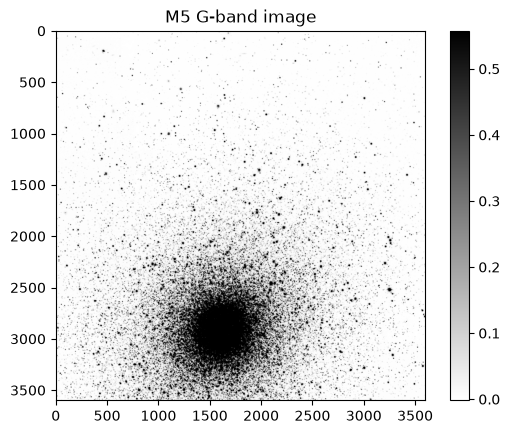

In [4]:
#make the figure
plt.figure()

#read in the data and header
data,header = fits.getdata('M5 G-band image.fits', header=True)

#use our custom made subroutine from above to plot the image
imdisplay(data)
plt.title("M5 G-band image")

Text(0.5, 1.0, 'M5 R-band image')

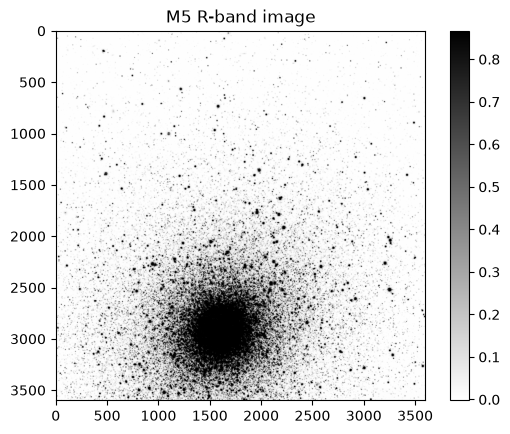

In [5]:
#make the figure
plt.figure()

#read in the data and header
data,header = fits.getdata('M5 R-band image.fits', header=True)

#use our custom made subroutine from above to plot the image
imdisplay(data)
plt.title("M5 R-band image")

In [6]:
from astropy.io import fits
from photutils.psf import fit_fwhm

def calc_fwhm(imagefilename, xyposlist):
    '''
    This function takes as input an image file name and a list of star pixel coordinates 
    and prints the FWHM for each star.  

    Stars should be bright, unsaturated, and isolated.

    INPUTS: 
    imagefilename: a string containing the image file name

    xyposlist: a list of x and y coordinates of the form [(x1,y1), (x2,y2)]
    This can contain an arbitrary number of stars.

    OUTPUT:
    fwhmlist: a list of FWHM
    '''
    image = fits.getdata(imagefilename)
    
    #use the photutils.psf.fit_fwhm function to fit a 2D PSF to the stars.
    fwhm = fit_fwhm(
        image,
        xypos=xyposlist,
        fwhm=4.0,        # initial guess, pixels
        fit_shape=21
    )
    print(f'The FWHM of the stars in {imagefilename} in pixels are {fwhm}')
    return(fwhm)

In [7]:
# Calculate FWHM for M5 G-band

M5Gstars = [(2310,838),(2546,999),(2320,1047),(2512,1177),(1906,1277)]

M5G_fwhm = calc_fwhm('M5 G-band image.fits', M5Gstars)

print("G-band FWHM:", M5G_fwhm)
print("Mean G-band FWHM:", np.mean(M5G_fwhm))
print("Median G-band FWHM:", np.median(M5G_fwhm))

The FWHM of the stars in M5 G-band image.fits in pixels are [5.64782557 5.60401002 5.8534596  5.86903849 6.09410038]
G-band FWHM: [5.64782557 5.60401002 5.8534596  5.86903849 6.09410038]
Mean G-band FWHM: 5.813686811931993
Median G-band FWHM: 5.853459595558811


In [10]:
#read in the G-band image
M5data_G, M5header_G = fits.getdata('M5 G-band image.fits',header=True)

In [12]:
# estimate the background counts in the image by computing the 
# mean and median excluding all pixels greater than 3-sigma above the mean
M5mean_G, M5median_G, M5std_G = sigma_clipped_stats(M5data_G, sigma=3.0)

Text(0, 0.5, 'Y (pixels)')

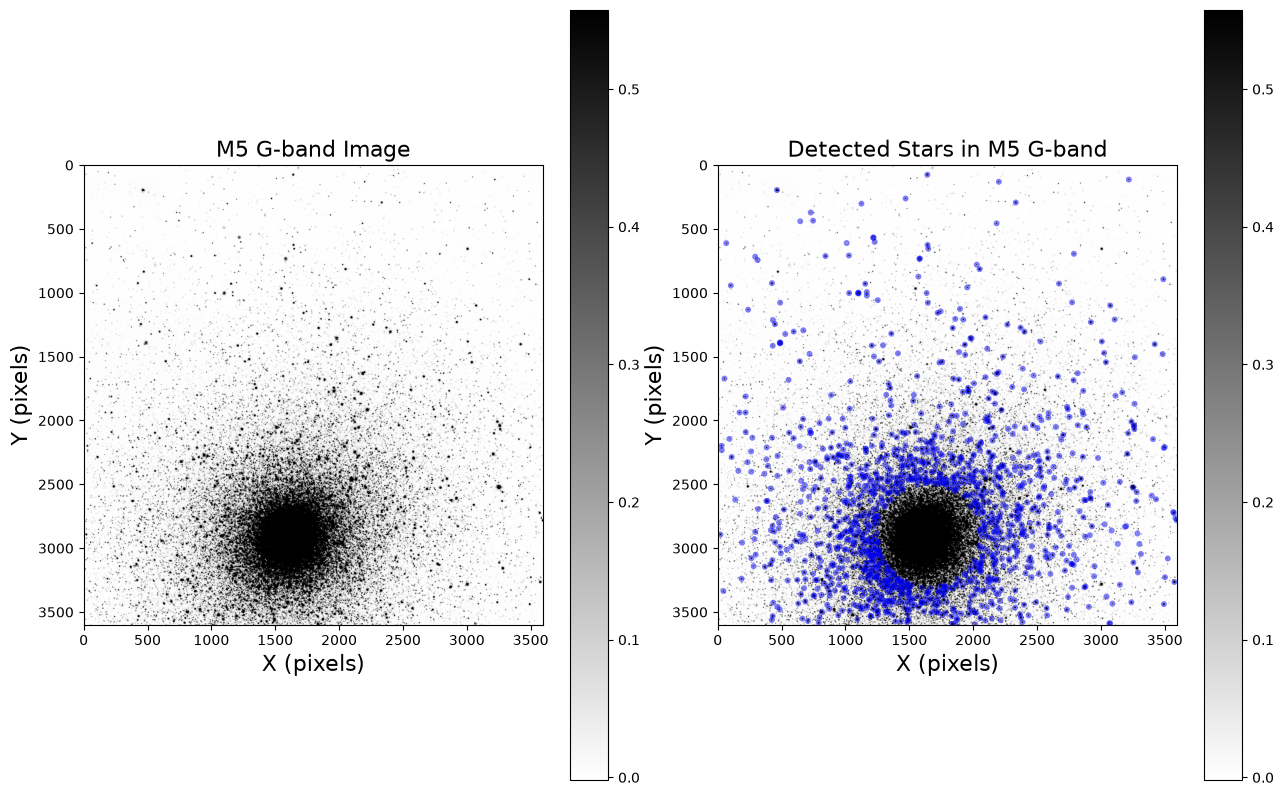

In [46]:
# set up daofind, with info about our image fwhm and the detection threshold
#*****************************************
# update with the FWHM that you measured using fit_fwhm
#you will need to update the threshold number based on plots you make in the next cell.
daofind = DAOStarFinder(fwhm=5.81, threshold=150.*M5std_G)

# detect sources, using the image - median, which subtracts the sky level from image, 
# assuming a sky that is constant across the iamge
M5sources_G = daofind(M5data_G - M5median_G)

# convert pixel locations of images to ra and dec using the image header
wcs_G = WCS(M5header_G)
M5ra_G,M5dec_G = wcs_G.wcs_pix2world(M5sources_G['xcentroid'],M5sources_G['ycentroid'],0)

# plot images and the sources.  using the subplot command we can plot figures side by side
#plots G-band image
plt.figure(figsize=(15,10))
#select the left plot
plt.subplot(1,2,1)
imdisplay(M5data_G)

plt.title('M5 G-band Image', fontsize=16)
plt.xlabel('X (pixels)', fontsize=16)
plt.ylabel('Y (pixels)', fontsize=16)

#plot B-band image with the positions of the sources overlaid
#select the right plot
plt.subplot(1,2,2)

# Only detect stars on outskirts
# exclude stars outside a certain radius in pixels
r_excluded = 400
x_center = 1650
y_center = 2900

# distance of detected stars from the center
dist_from_center = np.sqrt( (M5sources_G['xcentroid'] - x_center)**2 + (M5sources_G['ycentroid'] - y_center)**2 )
# filter out stars so only stars outside the radius are kept
M5Gfiltered_sources = M5sources_G[dist_from_center > r_excluded]

#Create a list of positions of all the stars, as determined by the DAOStarFinder above.  
#The transpose command puts the images into the correct format
positions = np.transpose((M5Gfiltered_sources['xcentroid'], M5Gfiltered_sources['ycentroid']))
#creates a set of circular apertues with r=15 pixels
apertures = CircularAperture(positions, r=15.)
imdisplay(M5data_G)
#plot the apertures.  the ';' at the end suppresses some messy output
apertures.plot(color='blue', lw=1.5, alpha=0.5);

plt.title('Detected Stars in M5 G-band', fontsize=16)
plt.xlabel('X (pixels)', fontsize=16)
plt.ylabel('Y (pixels)', fontsize=16)

Text(0.5, 1.0, 'M5 G-band')

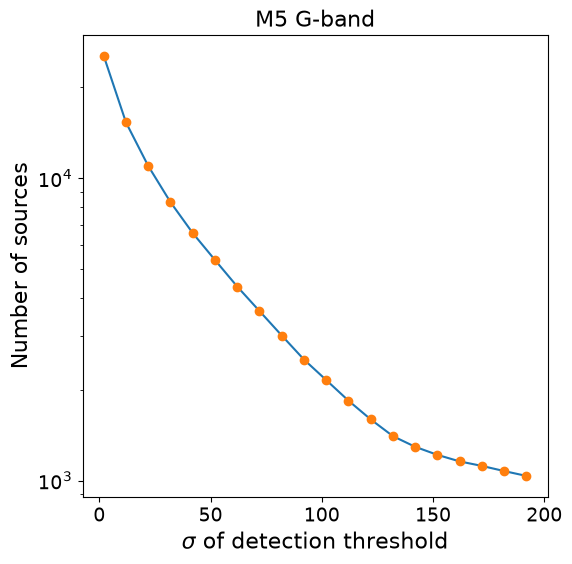

In [57]:
#This makes a plot of the number of sources for different detection thresholds for the G-band
#set up an array of thresholds
thresharr = np.arange(2.,200.,10)

#initialize an array that will hold the number of sources that are detected at each threshold
nsources_G = np.zeros(len(thresharr))

#loop through the thresholds to find how many sources are detected at each threshold
#************
#put in the appropriate FWHM you computed for this image earlier.
for ithresh,thresh in enumerate(thresharr):
    daofind = DAOStarFinder(fwhm=5.81, threshold=thresh*M5std_G)
    M5sources_Gtmp = daofind(M5data_G - M5median_G)
    # use filtered sources
    if M5sources_Gtmp is not None:
        dist_from_center = np.sqrt( (M5sources_Gtmp['xcentroid'] - x_center)**2 + (M5sources_Gtmp['ycentroid'] - y_center)**2 )
        M5sources_Gtmp = M5sources_Gtmp[dist_from_center > r_excluded]
        nsources_G[ithresh]=len(M5sources_Gtmp)
    else:
        nsources_G[ithresh]=0

#plot the number of sources at each threshold
fig,ax = plt.subplots(figsize=(6,6))
ax.plot(thresharr,nsources_G)
ax.plot(thresharr,nsources_G, 'o')
ax.set_yscale('log')
ax.set_ylabel('Number of sources', fontsize=16)
ax.set_xlabel(r'$\sigma$ of detection threshold', fontsize=16)
ax.tick_params(axis='x', labelsize=14)
ax.tick_params(axis='y', labelsize=14)
ax.set_title('M5 G-band', fontsize=16)

In [26]:
# Calculate FWHM for M5 R-band

M5Rstars = [(2322,1044),(2545,1001),(2673,928),(2776,1075),(2652,1309)]

M5R_fwhm = calc_fwhm('M5 R-band image.fits', M5Rstars)

print("R-band FWHM:", M5G_fwhm)
print("Mean R-band FWHM:", np.mean(M5R_fwhm))
print("Median R-band FWHM:", np.median(M5R_fwhm))

The FWHM of the stars in M5 R-band image.fits in pixels are [6.3381363  6.34301261 6.41543124 6.33026496 6.93942727]
R-band FWHM: [5.64782557 5.60401002 5.8534596  5.86903849 6.09410038]
Mean R-band FWHM: 6.473254476751111
Median R-band FWHM: 6.343012609597192


In [27]:
#read in the R-band image
M5data_R, M5header_R = fits.getdata('M5 R-band image.fits',header=True)

In [30]:
# estimate the background counts in the image by computing the 
# mean and median excluding all pixels greater than 3-sigma above the mean
M5mean_R, M5median_R, M5std_R = sigma_clipped_stats(M5data_R, sigma=3.0)

Text(0, 0.5, 'Y (pixels)')

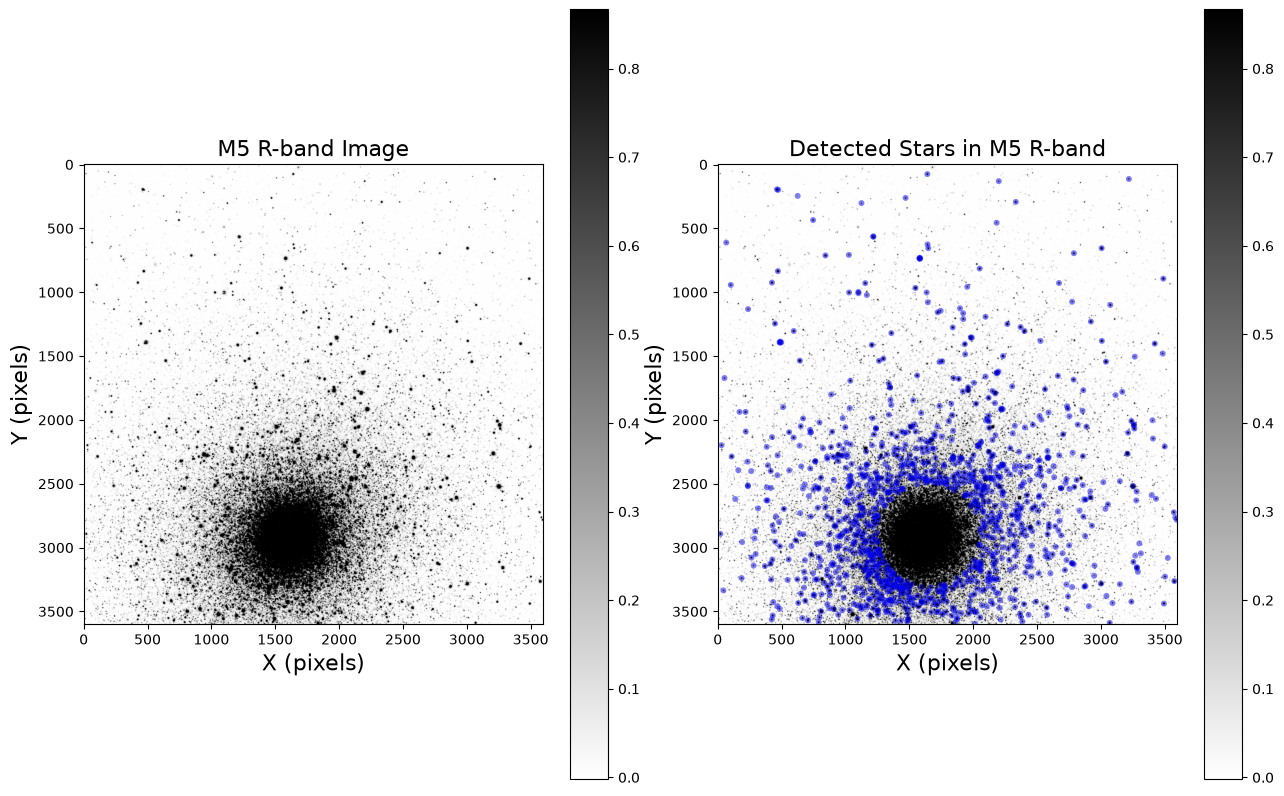

In [47]:
# set up daofind, with info about our image fwhm and the detection threshold
#*****************************************
# update with the FWHM that you measured using fit_fwhm
#you will need to update the threshold number based on plots you make in the next cell.
daofind = DAOStarFinder(fwhm=6.47, threshold=150.*M5std_R)

# detect sources, using the image - median, which subtracts the sky level from image, 
# assuming a sky that is constant across the iamge
M5sources_R = daofind(M5data_R - M5median_R)

# convert pixel locations of images to ra and dec using the image header
wcs_R = WCS(M5header_R)
M5ra_R,M5dec_R = wcs_R.wcs_pix2world(M5sources_R['xcentroid'],M5sources_R['ycentroid'],0)

# plot images and the sources.  using the subplot command we can plot figures side by side
#plots G-band image
plt.figure(figsize=(15,10))
#select the left plot
plt.subplot(1,2,1)
imdisplay(M5data_R)

plt.title('M5 R-band Image', fontsize=16)
plt.xlabel('X (pixels)', fontsize=16)
plt.ylabel('Y (pixels)', fontsize=16)

#plot B-band image with the positions of the sources overlaid
#select the right plot
plt.subplot(1,2,2)

# Only detect stars on outskirts
# exclude stars outside a certain radius in pixels
r_excluded = 400
x_center = 1650
y_center = 2900

# distance of detected stars from the center
dist_from_center = np.sqrt( (M5sources_R['xcentroid'] - x_center)**2 + (M5sources_R['ycentroid'] - y_center)**2 )
# filter out stars so only stars outside the radius are kept
M5Rfiltered_sources = M5sources_R[dist_from_center > r_excluded]

#Create a list of positions of all the stars, as determined by the DAOStarFinder above.  
#The transpose command puts the images into the correct format
positions = np.transpose((M5Rfiltered_sources['xcentroid'], M5Rfiltered_sources['ycentroid']))
#creates a set of circular apertues with r=15 pixels
apertures = CircularAperture(positions, r=15.)
imdisplay(M5data_R)
#plot the apertures.  the ';' at the end suppresses some messy output
apertures.plot(color='blue', lw=1.5, alpha=0.5);

plt.title('Detected Stars in M5 R-band', fontsize=16)
plt.xlabel('X (pixels)', fontsize=16)
plt.ylabel('Y (pixels)', fontsize=16)

Text(0.5, 1.0, 'M5 R-band')

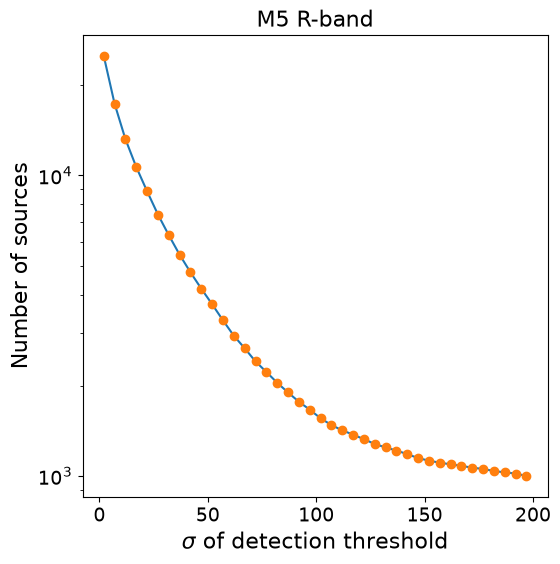

In [55]:
#This makes a plot of the number of sources for different detection thresholds for the G-band
#set up an array of thresholds
thresharr = np.arange(2.,200.,5)

#initialize an array that will hold the number of sources that are detected at each threshold
nsources_R = np.zeros(len(thresharr))

#loop through the thresholds to find how many sources are detected at each threshold
#************
#put in the appropriate FWHM you computed for this image earlier.
for ithresh,thresh in enumerate(thresharr):
    daofind = DAOStarFinder(fwhm=6.47, threshold=thresh*M5std_R)
    M5sources_Rtmp = daofind(M5data_R - M5median_R)
    # use filtered sources
    if M5sources_Rtmp is not None:
        dist_from_center = np.sqrt( (M5sources_Rtmp['xcentroid'] - x_center)**2 + (M5sources_Rtmp['ycentroid'] - y_center)**2 )
        M5sources_Rtmp = M5sources_Rtmp[dist_from_center > r_excluded]
        nsources_R[ithresh]=len(M5sources_Rtmp)
    else:
        nsources_R[ithresh]=0

#plot the number of sources at each threshold
fig,ax = plt.subplots(figsize=(6,6))
ax.plot(thresharr,nsources_R)
ax.plot(thresharr,nsources_R, 'o')
ax.set_yscale('log')
ax.set_ylabel('Number of sources', fontsize=16)
ax.set_xlabel(r'$\sigma$ of detection threshold', fontsize=16)
ax.tick_params(axis='x', labelsize=14)
ax.tick_params(axis='y', labelsize=14)
ax.set_title('M5 R-band', fontsize=16)

In [33]:
# Calculate background statistics for M5 G-band

M5mean_G, M5median_G,M5std_G =sigma_clipped_stats(M5data_G, sigma=3.0)

print("Mean:",M5mean_G)
print("Median:", M5median_G)
print("Standard deviation:",M5std_G)

Mean: 0.010361341
Median: 0.003136485
Standard deviation: 0.019552331


In [50]:
# Find stars in M5 G-band

M5daofind_G =DAOStarFinder(fwhm=5.81,threshold=150*M5std_G)

M5sources_G =M5daofind_G(M5data_G-M5median_G)

print("Number of detected stars:",len(M5Gfiltered_sources))
print(M5Gfiltered_sources[:10])

Number of detected stars: 1237
 id     xcentroid          ycentroid      ...    mag          daofind_mag     
--- ------------------ ------------------ ... ---------- ---------------------
  1 1641.1165278330197  75.23938341159948 ... -6.9816847    -2.923304562296104
  2 3219.2897003940257 113.50545939936207 ... -5.3591814    -1.262971344036656
  3 2200.6759350991033 130.40476459024663 ...  -5.499084   -1.3702525163009986
  4 463.93079360365823 195.17979161964305 ... -7.2902417    -2.629056051624395
  5 1470.8415621159666  261.6444506684323 ...  -5.551035   -1.4966434074051105
  6 2333.7760421008747  292.9162290556273 ...  -5.906742   -1.3880265154311284
  7  1125.035086642364 301.91609622009895 ... -4.9527054   -0.8472452881144408
  8  728.0126296001171  371.1959110724245 ... -4.2255306   -0.1657514535565678
  9  746.3437409559464  435.1690665579318 ... -5.3594074    -1.420180203159768
 10  645.8222161725026 439.98870825108816 ... -4.0438123 -0.016510746657043843


In [36]:
# Calculate background statistics for M5 R-band

M5mean_R, M5median_R, M5std_R = sigma_clipped_stats(M5data_R, sigma=3.0)

print("Mean:", M5mean_R)
print("Median:", M5median_R)
print("Standard deviation:", M5std_R)

Mean: 0.018974347
Median: 0.0050593317
Standard deviation: 0.0338163


In [51]:
# Find stars in M5 R-band

M5daofind_R = DAOStarFinder(fwhm=6.47,threshold=80*M5std_R)

M5sources_R = M5daofind_R(M5data_R - M5median_R)

print("Number of detected stars:", len(M5Rfiltered_sources))
print(M5Rfiltered_sources[:10])

Number of detected stars: 1132
 id     xcentroid          ycentroid      ...    mag         daofind_mag    
--- ------------------ ------------------ ... ---------- -------------------
  1   1641.12759148064  75.10183056499703 ... -7.0105557 -2.2961620656674175
  2  3219.260730842318  113.4901566134375 ... -6.2627406 -1.5081888368627907
  3 2200.6533313031346 130.37738282899613 ...  -6.085954 -1.3342598543513948
  4  463.8835943565586 195.05057840077475 ...  -8.017425  -2.869725849515341
  5  473.2157751359705  198.0457949188442 ... -5.8157372 -0.5801667283077004
  6  625.8518814474975 245.70126288710185 ... -4.8920374 -0.1854496109766021
  7 1470.7918687908511  261.6256079776332 ...   -6.42873  -1.693243719887819
  8 2333.9785880614522  292.7804043970433 ... -6.6340213 -1.5092236788511693
  9 1125.1212317160368 301.93915349284697 ...  -5.473371 -0.3344471650572128
 10  746.1905124331253  435.0644220389028 ... -6.4345875 -1.3547093187988266


In [58]:
from astropy.coordinates import SkyCoord
from astropy import units as u

# Convert pixel coordinates to RA and DEC
M5wcs_G =WCS(M5header_G)
M5wcs_R =WCS(M5header_R)

M5ra_G, M5dec_G = M5wcs_G.all_pix2world( M5Gfiltered_sources['x_centroid'], M5Gfiltered_sources['y_centroid'], 0)

M5ra_R, M5dec_R= M5wcs_R.all_pix2world( M5Rfiltered_sources['x_centroid'], M5Rfiltered_sources['y_centroid'], 0)

print("G coordinates:", len(M5ra_G))
print("R coordinates:", len(M5ra_R))

#this creates a SkyCoord object containing the G and R catalogs
M5G_catalog = SkyCoord(ra=M5ra_G*u.degree, dec=M5dec_G*u.degree)
M5R_catalog = SkyCoord(ra=M5ra_R*u.degree, dec=M5dec_R*u.degree)

#this matches the two catalogs and outputs an array of indices, idx that when passed to v_catalog
#gives the ids of the match sources in the b_catalog.
idx, d2d, d3d = M5G_catalog.match_to_catalog_sky(M5R_catalog)

# we are going to keep matches that have offsets less than 2 arcseconds
matchflag = d2d < 0.4/3600*u.deg

bmag = M5Gfiltered_sources['mag'][matchflag]
vmag = M5Rfiltered_sources['mag'][idx[matchflag]]

print("Matched stars:", sum(matchflag))

KeyError: 'x_centroid'